# 1. Import Libraries and Dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

auto_mpg = fetch_ucirepo(id=9)

# 2. Creating a Dataset

In [4]:
data = auto_mpg.data.original

In [5]:
df = pd.DataFrame(data)

In [6]:
df.head(2)

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
0,"chevrolet,chevelle,malibu",8,307.0,130.0,3504,12.0,70,1,18.0
1,"buick,skylark,320",8,350.0,165.0,3693,11.5,70,1,15.0


In [7]:
df.tail(2)

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
396,"ford,ranger",4,120.0,79.0,2625,18.6,82,1,28.0
397,"chevy,s-10",4,119.0,82.0,2720,19.4,82,1,31.0


# 3. Observing the Dataframe

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_name      398 non-null    object 
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   mpg           398 non-null    float64
dtypes: float64(4), int64(4), object(1)
memory usage: 28.1+ KB


In [9]:
df.describe()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


## 1. Checking for Null Values

In [10]:
df.isnull().sum()

,0
car_name,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


In [11]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].mean())

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_name      398 non-null    object 
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   mpg           398 non-null    float64
dtypes: float64(4), int64(4), object(1)
memory usage: 28.1+ KB


## 2. Check for NAN Values

In [13]:
df.isna().sum()

,0
car_name,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


## 3. Checking for Duplicate Values

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.drop_duplicates()

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_name      398 non-null    object 
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   mpg           398 non-null    float64
dtypes: float64(4), int64(4), object(1)
memory usage: 28.1+ KB


# 4. Data Visualisation

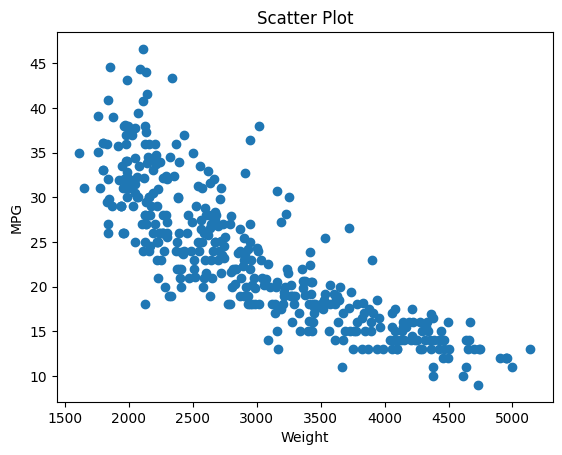

In [17]:
xaxis = df['weight']
yaxis = df['mpg']

plt.scatter(xaxis, yaxis)

plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('Scatter Plot')

plt.show()

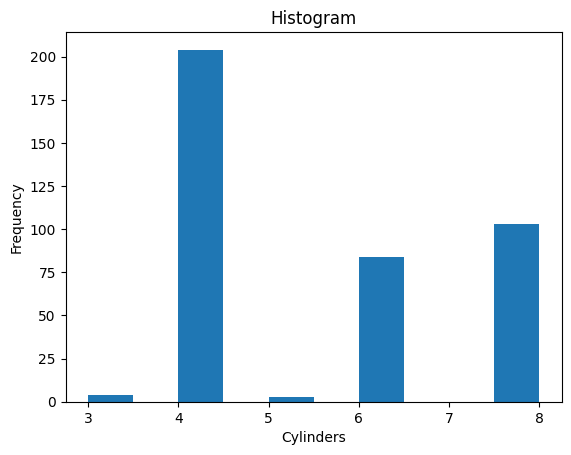

In [18]:
xaxis = df['cylinders']

plt.hist(xaxis)

plt.xlabel('Cylinders')
plt.ylabel('Frequency')
plt.title('Histogram')

plt.show()

#1.What are mean, median, minimum, and maximum miles per gallon(MPG)?

In [19]:
print("Mean MPG:", df['mpg'].mean())
print("Median MPG:", df['mpg'].median())
print("Minimum MPG:", df['mpg'].min())
print("Maximum MPG:", df['mpg'].max())

Mean MPG: 23.514572864321607
Median MPG: 23.0
Minimum MPG: 9.0
Maximum MPG: 46.6


#2 Compare average MPG for cars eith 4,6,8 cylinders.

cylinders
4    29.286765
6    19.985714
8    14.963107
Name: mpg, dtype: float64


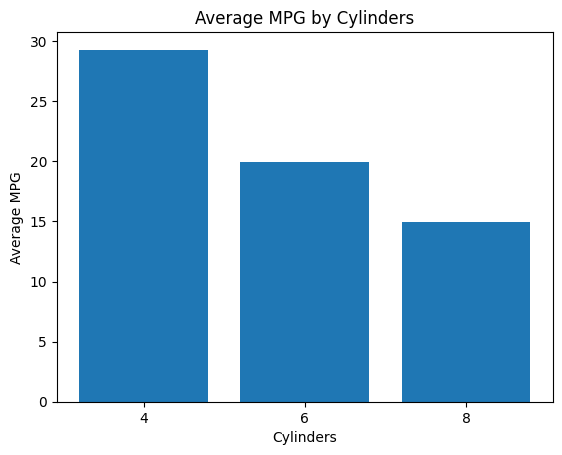

In [20]:
avg_mpg = df[df['cylinders'].isin([4, 6, 8])].groupby('cylinders')['mpg'].mean()

print(avg_mpg)

plt.bar(avg_mpg.index.astype(str), avg_mpg.values)

plt.xlabel('Cylinders')
plt.ylabel('Average MPG')
plt.title('Average MPG by Cylinders')

plt.show()

#3. Which model year has the highest MPG?

In [23]:
avg_mpg = df.groupby('model_year')['mpg'].mean()

print("Model year with highest average MPG:", avg_mpg.idxmax())
print("Average MPG:", avg_mpg.max())

Model year with highest average MPG: 80
Average MPG: 33.69655172413793


#4. List the 10 most fuel-efficient cars.

In [22]:
top10 = df.sort_values('mpg', ascending=False).head(10)[['car_name', 'model_year', 'mpg']]

print(top10)

                            car_name  model_year   mpg
322                        mazda,glc          80  46.6
329              honda,civic,1500,gl          80  44.6
325             vw,rabbit,c,(diesel)          80  44.3
394                        vw,pickup          82  44.0
326               vw,dasher,(diesel)          80  43.4
244  volkswagen,rabbit,custom,diesel          78  43.1
309                        vw,rabbit          80  41.5
330             renault,lecar,deluxe          80  40.9
324                       datsun,210          80  40.8
247                   datsun,b210,gx          78  39.4


#5. Check missing values, especially horsepower.

In [24]:
print(df.isnull().sum())

print("Missing horsepower values:", df['horsepower'].isnull().sum())
print("Missing horsepower %:", round(df['horsepower'].isnull().mean() * 100, 2))

df[df['horsepower'].isnull()]

car_name        0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64
Missing horsepower values: 0
Missing horsepower %: 0.0


,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg


#6. Compare average MPG by origin.

In [25]:
# Pandas
avg_pandas = df.groupby('origin')['mpg'].mean()
print(avg_pandas)

# NumPy
for o in sorted(df['origin'].unique()):
    mpg_values = df[df['origin'] == o]['mpg'].to_numpy()
    print(o, "-> mean:", np.mean(mpg_values), "median:", np.median(mpg_values), "std:", np.std(mpg_values))

origin
1    20.083534
2    27.891429
3    30.450633
Name: mpg, dtype: float64
1 -> mean: 20.083534136546184 median: 18.5 std: 6.390021868331153
2 -> mean: 27.89142857142857 median: 26.5 std: 6.675728806807599
3 -> mean: 30.450632911392404 median: 31.6 std: 6.051380706928186
